In [37]:
import cobra 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from cobra.flux_analysis import loopless_solution


# metabolic modeling of cyanobacteria - FBA
## Goal : compare metabolism of (i) WT cyanobacteria, (ii) a mutant with native phosphorespiration pathway deleted (dCCM), and (iii) the mutant dCCM with BAHC reactions added (pathway to recycle C2 compound produced by rubisco)
### We will use the previously published metabolic network iMS837 to simulate fluxes in the WT, and modify the network to model the (ii) and (iii) cases


In this notebook, we create the mutant dCCM : 
- remove the carboxysome 

In [2]:
BASE_FOLDER='/home/nathan/PhD/04.Computational/202609_BHAC_cyano/'
INPUT_FOLDER=f'{BASE_FOLDER}1_data/'
RESULTS_FOLDER=f'{BASE_FOLDER}3_results/'

Load cobra model 

In [3]:
model = cobra.io.load_json_model(f'{INPUT_FOLDER}iMS837.json')

Set bounds on exchange reactions to simulate the proper experimental conditions

In [91]:
### nitrate is the only N-source -> no ammonium/ammonia
model.reactions.EX_nh4_e.lower_bound = 0
## we will constrain atmospheric CO2 in %, so we block hco3 uptake 
model.reactions.EX_hco3_e.lower_bound = 0

##modify co2 bound ? 
model.reactions.EX_co2_e.lower_bound = -1

create mutant : delete all reactions in carboxysome and replace 99:1 rubisco reaction with a 3:1 co2/o2 one 

In [92]:
# model.reactions.remove_reactions([r.id for r in model.reactions if 'cx' in r.compartments])
rxn_cx=list(set([r for r in model.reactions for m in r.metabolites if 'carboxyzome' in m.compartment ]))
##remove these from the model 
model.remove_reactions([r.id for r in rxn_cx],remove_orphans=True)

In [93]:
## add cytosolic rubisco reaction
RBPCc=cobra.Reaction('RBPCc')
model.add_reactions([RBPCc])
##add mets  4 rb15bp_c + 3 co2_c + 3 h2o_c + 1 o2_c --> 7 3pg_c + 1 2pglyc_c + 8 h_c
RBPCc.add_metabolites({'rb15bp_c':-4,'co2_c':-3,'h2o_c':-3,'o2_c':-1,'3pg_c':7,'2pglyc_c':1,'h_c':8})



Ignoring reaction 'RBPCc' since it already exists.


ValueError: Reaction 'RBPCc' does not belong to a model. Either add the reaction to a model or use Metabolite objects instead of strings as keys.

create BHAC mutant : add 4 BHAC reactions 


In [94]:

## --- new metabolite: β-hydroxyaspartate ---
hyasp_c = cobra.Metabolite(
    'hyasp_c',
    formula='C4H6NO5',
    charge=-1,
    name='beta-Hydroxyaspartate',
    compartment='cytosol'
)
model.add_metabolites([hyasp_c])

## --- BhcA: Aspartate-glyoxylate aminotransferase ---
BhcA = cobra.Reaction('BhcA')
BhcA.name = 'Aspartate-glyoxylate aminotransferase'
BhcA.lower_bound = -1000.0
BhcA.upper_bound = 1000.0
model.add_reactions([BhcA])
BhcA.add_metabolites({'asp__L_c': -1, 'glx_c': -1, 'oaa_c': 1, 'gly_c': 1})

## --- BhcC: β-Hydroxyaspartate aldolase ---
BhcC = cobra.Reaction('BhcC')
BhcC.name = 'beta-Hydroxyaspartate aldolase'
BhcC.lower_bound = -1000.0
BhcC.upper_bound = 1000.0
model.add_reactions([BhcC])
BhcC.add_metabolites({'glx_c': -1, 'gly_c': -1, 'hyasp_c': 1})

## --- BhcB: β-Hydroxyaspartate dehydratase ---
BhcB = cobra.Reaction('BhcB')
BhcB.name = 'beta-Hydroxyaspartate dehydratase'
BhcB.lower_bound = -1000.0
BhcB.upper_bound = 1000.0
model.add_reactions([BhcB])
BhcB.add_metabolites({'hyasp_c': -1, 'iasp_c': 1, 'h2o_c': 1, 'h_c': 1})

## --- BhcD: Iminosuccinate reductase ---
BhcD = cobra.Reaction('BhcD')
BhcD.name = 'Iminosuccinate reductase'
BhcD.lower_bound = 0.0       # NADH-dependent reduction, physiologically irreversible
BhcD.upper_bound = 1000.0
model.add_reactions([BhcD])
BhcD.add_metabolites({'iasp_c': -1, 'nadh_c': -1, 'h_c': -2, 'asp__L_c': 1, 'nad_c': 1})

Ignoring reaction 'BhcA' since it already exists.


ValueError: Reaction 'BhcA' does not belong to a model. Either add the reaction to a model or use Metabolite objects instead of strings as keys.

In [ ]:
## save model in json 
# cobra.io.save_json_model(model,f'{INPUT_FOLDER}iMS837_BHAC.json')

In [95]:
###biomass is model.reactions.BOF
model.objective='BOF'

In [96]:
###loopless FBA
print(model.optimize())
solution = model.optimize()          # regular FBA first, to get the objective
sol = loopless_solution(model, fluxes=solution.fluxes)  # remove thermodynamically infeasible internal loops
dfsol=sol.fluxes.to_frame()

<Solution 0.026 at 0x7d6f5fe30810>


In [97]:
dfsol.loc['EX_co2_e']

fluxes   -1.0
Name: EX_co2_e, dtype: float64

analyze flux of BHAC reactions 

In [98]:
dfsol.loc[['BhcA','BhcB','BhcC','BhcD']]


,fluxes
BhcA,0.011605
BhcB,0.138860
BhcC,0.138860
BhcD,0.138853


In [99]:
### glyclt_c is glycolate , ### RBPCcx is rubisco reaction
## we are interested in the fluxes that consume produces the following metabolites 
## glycine gly_c, serine ser__L_c, aspartate asp__L_c
rxn_13cmets=list(set([r.id for r in model.reactions for m in r.metabolites if m.id in ['gly_c','ser__L_c','asp__L_c']]))
##decompose in 3 lists for each met 
rxn_ser= [r.id for r in model.reactions if 'ser__L_c' in [m.id for m in r.metabolites]]
rxn_gly= [r.id for r in model.reactions if 'gly_c' in [m.id for m in r.metabolites]]
rxn_asp= [r.id for r in model.reactions if 'asp__L_c' in [m.id for m in r.metabolites]]
rxn_glx= [r.id for r in model.reactions if 'glx_c' in [m.id for m in r.metabolites]]

In [100]:
dfsol.loc[rxn_ser]
# dfsol.loc[['AGTi','SPTr']] ##this is SGat in the diagram

,fluxes
TRPS1,0.001830
PSP_L,0.000000
SERAT,0.001180
TRPS2,0.000000
SPTr,-0.043086
GHMT2r,-0.052953
SERTRS,0.006857


### look at metabolite turnover e.g. NADH

In [101]:
def flux_of_metabolite(S_df, fluxes_df:pd.Series, MET:str,lb_abs=1e-1)->pd.DataFrame:
    """given the stoicheometry matrix, the flux dataframe for all reactions and the metabolite we look for 
        we get the values of fluxes that produce or consume this mets, 
        returns a dataframe with the fluxes values of the reactions that produce or consume the metabolite"""
    S_T_df = S_df.T
    ##MET_rxns_stoich is a series of reactions with how much of the metabolite is produced or consumed
    MET_rxns_stoich=S_T_df[MET]
    MET_rxns_stoich=MET_rxns_stoich[MET_rxns_stoich!=0] ##drop 0 values : rxn that dont produce or consume the metabolite
    #multiply fluxes values by the stoicheometry of the metabolite in the reaction
    df_met_flux=fluxes_df.loc[MET_rxns_stoich.index].mul(MET_rxns_stoich, axis=0)
    # drop low values
    df_met_flux=df_met_flux[abs(df_met_flux)>lb_abs] 
    return df_met_flux ##get the fluxes values of the reactions that produce or consume the metabolite
S=cobra.util.array.create_stoichiometric_matrix(model)
S_df=pd.DataFrame(S,columns=[r.id for r in model.reactions],index=[m.id for m in model.metabolites])


In [102]:
met='nadh_c'
df_met=flux_of_metabolite(S_df,dfsol,met)
def filter_absthresh(df,abs_tresh=0):
    return df[abs(df)>abs_tresh]

dfplot=filter_absthresh(df_met).dropna()

In [103]:
display(dfplot)
model.reactions.BhcD

,fluxes
GLYDHDA,-0.371180
GLYCLTDx,0.411548
BhcD,-0.138853


Reaction identifier,BhcD
Name,Iminosuccinate reductase
Memory address,0x7d6f6efebfd0
Stoichiometry,2 h_c + iasp_c + nadh_c --> asp__L_c + nad_c 2 H+ + Iminoaspartate + NADH --> L-Aspartate + NAD+
GPR,
Lower bound,0.0
Upper bound,1000.0


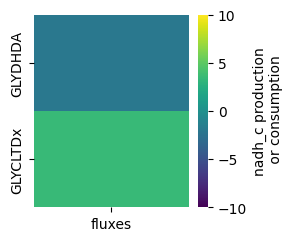

In [46]:
import colorsys
import matplotlib.ticker as ticker

fig,ax=plt.subplots(1,1,figsize=(2.5, 2.5))


hm=sns.heatmap(dfplot,cmap='viridis',ax=ax,vmin=-10,vmax=10,    center=0,
)
step = 1
# ax.set_yticks(np.arange(0, len(dfplot), step)+0.5)
# ax.set_yticklabels(dfplot.index[::step])

# ax.set_xticklabels(['WT','TM6'])
# label colorbar
cbar = hm.collections[0].colorbar
cbar.set_label(f'{met} production\n or consumption')
##save
# plt.savefig(f'{config.SUPP_PLOTS_FOLDER}/SuppFig_{met}_fluxofmet_2conds.svg',dpi=300,bbox_inches='tight')

In [14]:
for r in rxn_gly:
    print(r,model.reactions.get_by_id(r).reaction)

GLYCL gly_c + nad_c + thf_c --> co2_c + mlthf_c + nadh_c + nh4_c
PRAGSr atp_c + gly_c + pram_c --> adp_c + gar_c + h_c + pi_c
GLYDHDA gly_c + h2o_c + nad_c <=> glx_c + h_c + nadh_c + nh4_c
AMPTASECG cgly_c + h2o_c --> cys__L_c + gly_c
GTHS atp_c + glucys_c + gly_c --> adp_c + gthrd_c + h_c + pi_c
GHMT2r ser__L_c + thf_c <=> gly_c + h2o_c + mlthf_c
GLYCOX1 gly_c + o2_c --> h2o2_c + imgly_c
AGTi ala__L_c + glx_c --> gly_c + pyr_c
GLYTRS atp_c + gly_c + trnagly_c --> amp_c + glytrna_c + ppi_c
BhcA asp__L_c + glx_c <=> gly_c + oaa_c
BhcC glx_c + gly_c <=> hyasp_c


compare growth rate with different % of Co2

In [90]:
co2_levels = {'1pct': 1.0, '0.5pct': 0.13, '0.3pct': 0.3}
reference_pct = 0.04          # e.g. ambient air, your calibration point
reference_bound = 2.0         # mmol/gDW/h — the CO2 uptake bound you've validated growth against at reference_pct

for label, pct in co2_levels.items():
    scaled_bound = reference_bound * (pct / reference_pct)
    with model:  # context manager: change reverts after the block
        model.exchanges.get_by_id('EX_co2_e').lower_bound = -scaled_bound
        sol = model.optimize()
        print(label, '-> CO2 bound:', -scaled_bound, '| growth:', sol.objective_value)

1pct -> CO2 bound: -50.0 | growth: 0.2187355095909811
0.5pct -> CO2 bound: -6.5 | growth: 0.16686532694334208
0.3pct -> CO2 bound: -15.0 | growth: 0.2187355095909478


visualization with escher

In [16]:
# from bioemma.workflow import build_outputs
# from bioemma.visualization import VisualizationOptions


# result = build_outputs(
#     model=model,
#     pathway="rn00630",
#     output_dir=RESULTS_FOLDER,
#     database="BIGG",
#     run_fba=False,
#        visualization_options=VisualizationOptions(
#         scaling_factor=4,
#         axis_epsilon=2,
#         markers_dist=10,
#         metabolite_label_shift=(10, 10),
#         reaction_label_shift=(10, 10),
#         canvas_margin_x=160,
#         canvas_margin_y=160,
#         multimarker_distance_fraction=0.3,
#         use_constant_multimarker_distance=False,
#         constant_multimarker_distance=300,
#         axis_offset=20,
#         secondary_metabolite_distance=None,
#         secondary_metabolite_spacing=None,
#     ),
# )

# escher_map = result.escher_map
# kegg_reconstruction = result.kegg_reconstruction

In [17]:
# import json
# import escher

# builder = escher.Builder(
#     map_json=json.dumps(escher_map)
# )

# builder.save_html(f'{RESULTS_FOLDER}/escher_map_BHAC.html')